In [863]:
import sys
from pathlib import Path
import importlib

sys.path.insert(0, str(Path.cwd().parent / "src"))

import cosmology
importlib.reload(cosmology)

In [875]:
# from scipy.integrate import quad
# from scipy.stats import norm
# import numpy as np
# import multiprocessing as mp
# import astropy.units as u
# from astropy import constants as const
# from tqdm import tqdm

# from cosmology import ReadCosmology
# from eagle_query import initiate_query

# def _init_worker(processor):
#     global _worker_processor
#     _worker_processor = processor

# def _compute_spectrum_worker(args):
#     doppler, sightline_pos = args
#     return _worker_processor._calc_single_spectrum(doppler = doppler, sightline_pos = sightline_pos)

# class Spectrum:
#     def __init__(self, username: str,
#                  password: str, 
#                  simName: str = "L0100N1504", 
#                  snapNum: int = 12,
#                  fgas: float = 0.6, 
#                  alpha: float = 2,
#                  sightline_axis: int = 2
#                 ) -> None:

#         """Initialise the spectrum using an EAGLE snapshot"""

#         if not np.isfinite(fgas) or not 0 <= fgas <= 1:
#             raise ValueError("fgas must be between 0 and 1")

#         if not np.isfinite(alpha):
#             raise ValueError("alpha must be finite")

#         if sightline_axis not in (0, 1, 2):
#             raise ValueError("sightline_axis must be 0, 1 or 2")

#         self.subhalos     = initiate_query(username, password, simName, snapNum)
#         self.num_subhalos = np.shape(self.subhalos)[0]

#         self.z        = self.subhalos['redshift'][0]
#         self.fgas     = fgas
#         self.scaleFac = 1 / (1 + self.z)
#         self.alpha    = alpha

#         self.cosmology  = ReadCosmology(z = self.z)
#         self.cosmo_dict = self.cosmology.read_cosmo()

#         self.boxSizeCo   = 100 * u.Mpc
#         self.boxSizePr   = self.boxSizeCo * self.scaleFac

#         self.sightline_axis = sightline_axis

#         self.integral, self.integral_error = quad(       # Integral to calculate the column density.
#             lambda q: 1 / (1 + q**2)**self.alpha, 
#             0, 
#             float("inf")
#         )

#         if not np.isfinite(self.integral):
#             raise ValueError("The integral is not finite.")

#         self.nHh = self._compute_nHh()      # Hydrogen number density at the virial radius in cm^-3.
        
#     def _compute_nHh(self) -> u.Quantity:
#         """
#         Calculate the hydrogen number density at the halo virial radius.
    
#         The density is assumed to be the same for every halo and is derived
#         from the mean hydrogen density within the virial radius, assuming
#         a halo overdensity of 200 relative to the critical density.
    
#         The hydrogen density at the virial radius is determined using the
#         power-law density profile specified by self.alpha.
    
#         Returns
#         -------
#         nHh : astropy.units.Quantity
#             Hydrogen number density at the virial radius, in cm^-3.
#         """
#         rhocritz = self.cosmo_dict['Quantities']['rhocrit']
#         Omegab   = self.cosmo_dict['Constants']['Omegab']
#         Omegam   = self.cosmo_dict['Constants']['Omegam']
#         X        = self.cosmo_dict['Constants']['X']
#         fgas     = self.fgas
    
#         omegab = Omegab / Omegam
    
#         rhomeanH_h = 200 * rhocritz * X * fgas * omegab
#         rhoH_h = ((3 - self.alpha) / 3) * rhomeanH_h
#         nHh = (rhoH_h / const.m_p).to(1 / u.cm**3)
    
#         return nHh.to(1 / u.cm**3)

#     def _compute_NHI(self, 
#                     R_h: u.Quantity = 100 * u.kpc, 
#                     b: u.Quantity = 1 * u.Mpc, 
#                     Gamma0: u.Quantity = None, 
#                     alphaB: u.Quantity = None
#                    ) -> u.Quantity:
#         """
#         Calculates the column density for each selected halo using the corresponding
#         impact parameter.

#         Parameters
#         ----------
#         R_h: astropy.units.Quantity, optional
#             The virial radius of the selected halo.
#             Default is 100 kpc

#         b: astropy.units.Quantity, optional
#             The impact prameter of the selected halo.
#             Default is 1 Mpc.

#         Gamma0: astropy.units.Quantity, optional
#             The neutral hydrogen photoionization rate. [1/s]
#             If None, the default value is used.

#         alphaB: astropy.units.Quantity, optional
#             The Case-B recombination coefficient for hydrogen. [cm^3/s]
#             If None, the default value is used.

#         Returns
#         -------
#         NHIs: astropy.units.Quantity, [cm^-2]
#             Quantity array containing the column density for each selected halo.
        
#         """
        
#         # Normalized parameters
#         alphaB_norm = 3e-13 * u.cm**3 / u.s    # Normalized to T = 1.5x10^4 K 
#         Gamma0_norm = 0.882e-12 / u.s          # Normalized to z = 3.0

#         nH_h     = self.nHh
#         alpha    = self.alpha

#         I = self.integral

#         if Gamma0 is None:
#             Gamma0 = Gamma0_norm

#         if alphaB is None:
#             alphaB = alphaB_norm

#         NHI_h = 2 * (alphaB / Gamma0) * nH_h**2 * R_h * I

#         NHIs = (NHI_h * (R_h / b)**(2*alpha - 1)).to(u.cm**-2)

#         return NHIs.to(u.cm**-2)
        
#     def _generate_sightline_pos(self):
#         """
#         Method to generate a random sightline starting position within the simulation volume.
#         The sightline starts at axis coordinate zero

#         Returns
#         -------
#         astropy.units.Quantity, shape (1, 3) [pMpc]
        
#         """

#         # Axis sightline travels along
#         sightline_axis = self.sightline_axis
        
#         # Generate random sightline starting coordinate 
#         init_coords = np.random.rand(3) * self.boxSizePr

#         # Fix axis coordinate to zero (arbitrary)
#         init_coords[sightline_axis] = 0.0 * u.Mpc

#         return init_coords.to(u.Mpc)

#     def _calc_periodic_distance(self, delta_r: u.Quantity, boxsize: u.Quantity) -> u.Quantity:
#         """
#         Calculate displacement vectors using periodic boundary conditions.

#         Parameters
#         ----------
#         delta_r: astropy.units.Quantity, required
#             Displacement vector(s) between positions with units of length.

#         boxsize: astropy.units.Quantity, required
#             Boxsize of the EAGLE simulation, with compatiable unit of length.

#         Returns
#         -------
#         periodic_delta_r: astropy.units.Quantity
#             Displacement vector(s) adjusted to the minimum-image convention,
#             such that each component lies within [-boxsize/2, boxsize/2).
        
#         """
#         periodic_delta_r = delta_r - (boxsize * np.floor((delta_r / boxsize) + 0.5))
        
#         return periodic_delta_r.to(u.Mpc)
        

#     def _compute_impact_params(self, sightline_pos) -> u.Quantity:
#         """
#         Return impact parameters from one sightline position to all halo centres.
    
#         Parameters
#         ----------
#         sightline_pos : astropy.units.Quantity, shape (3,)
#             Sightline starting coordinates in proper Mpc.
    
#         Returns
#         -------
#         astropy.units.Quantity, shape (num_subhalos,)
#             Impact parameters in Mpc.
#         """

#         sightline_pos = u.Quantity(sightline_pos).to(u.Mpc)

#         # Halo position within simulation volume [cMpc]
#         halo_pos_co = np.column_stack((
#             self.subhalos['x'],
#             self.subhalos['y'],
#             self.subhalos['z']
#         )) * u.Mpc 
        
#         # Halo position within simulation volume [pMpc]
#         halo_pos_pr = halo_pos_co * self.scaleFac
    
#         # Displacement vectors from sightline starting pos to halo pos [pMpc]
#         delta_r          = halo_pos_pr - sightline_pos
#         delta_r_periodic = self._calc_periodic_distance(delta_r, self.boxSizePr)

#         # Select the two perpendicular axes
#         possible_axes = [i for i in range(3) if i != self.sightline_axis]

#         # Calculate the impact parameters
#         bs = np.linalg.norm(delta_r_periodic[:, possible_axes], axis = 1)

#         assert bs.shape == (len(self.subhalos['x']),), "Impact parameter array is not 1-dimensional"
    
#         return bs.to(u.Mpc)
    
#     def _calc_halo_vels(
#         self,
#         sightline_pos: u.Quantity
#     ) -> u.Quantity:
#         """
#         Calculate the line-of-sight velocity of each halo relative to a sightline.
    
#         The total velocity combines the Hubble-flow velocity, calculated from
#         the periodic line-of-sight displacement, and the halo's peculiar
#         velocity along the line-of-sight axis.
    
#         Parameters
#         ----------
#         sightline_pos : astropy.units.Quantity
#             Position of the sightline in the simulation box, with units of
#             length.
    
#         Returns
#         -------
#         total_los_halo_vel : astropy.units.Quantity
#             Total line-of-sight velocity of each halo, including Hubble flow
#             and peculiar velocity, in km/s.
#         """
#         # Select the line-of-sight axis
#         sightline_axis = self.sightline_axis
#         axis = ['x', 'y', 'z'][sightline_axis]
#         vel_axis = ['vx', 'vy', 'vz'][sightline_axis]
    
#         # Select line-of-sight coordinates
#         los_halo_pos_pr = self.subhalos[axis] * u.Mpc * self.scaleFac
#         los_sightline_pos = sightline_pos[sightline_axis]
    
#         # Calculate halo displacement, accounting for periodic boundaries
#         los_halo_displacement = los_halo_pos_pr - los_sightline_pos
#         los_halo_displacement_periodic = self._calc_periodic_distance(
#             los_halo_displacement, self.boxSizePr
#         )
    
#         # Calculate Hubble-flow and peculiar velocities
#         hubble_vel = (
#             self.cosmo_dict['Quantities']['H'] * los_halo_displacement_periodic
#         )
#         los_halo_vel = self.subhalos[vel_axis] * u.km / u.s
    
#         total_los_halo_vel = hubble_vel + los_halo_vel
    
#         return total_los_halo_vel.to(u.km / u.s)

#     def _calc_single_spectrum(self, 
#                              doppler: u.Quantity = 23 * u.km / u.s,
#                              vel_res: u.Quantity = 1 * u.km / u.s, 
#                              sightline_pos: u.Quantity = None
#                             ) -> tuple:
#         """
#         Calculate the optical depth and transmitted flux along a single sightline.

#         Parameters
#         ----------
#         doppler: astropy.units.Quantity, optional
#             Doppler parameter to describe thermal motion of the hydrogen atoms. [km/s]
#             Default is 23 km/s

#         vel_res: astropy.units.Quantity, optional
#             Increment of velocity grid. [km/s]
#             Default is 1 km/s

#         sightline_pos: astropy.units.Quantity, optional
#             Starting position for the sightline.
#             Default is None
            
#         Returns
#         -------
#         NHIs: astropy.units.Quantity
#             Neutral hydrogen column density for each selected halo. [cm^-2]

#         vel_grid: astropy.units.Quantity
#             Velocity grid for which the spectrum is evaluated on. [km/s]

#         flux: numpy.ndarray
#             Transmitted flux as a function of velocity.

#         tau_v: numpy.ndarray
#             Optical depth as a function of velocity.
            
#         """
        
#         doppler_value = u.Quantity(doppler).to_value(u.km / u.s)
#         vel_res_value = u.Quantity(vel_res).to_value(u.km / u.s)
        
#         if not np.isfinite(doppler_value) or doppler_value <= 0:
#             raise ValueError("doppler must be finite and positive.")
        
#         if not np.isfinite(vel_res_value) or vel_res_value <= 0:
#             raise ValueError("vel_res must be finite and positive.")

#         if sightline_pos is None:
#             sightline_pos = self._generate_sightline_pos()

#         impact_params = self._compute_impact_params(sightline_pos)

#         in_range      = impact_params < 5 * u.Mpc              # Limit maximum impact parameter to remove minimally contributing halos
#         R_hs_in_range = self.subhalos['r200'][in_range] * u.kpc
#         bs_in_range   = impact_params[in_range]
#         NHIs          = self._compute_NHI(R_h = R_hs_in_range, b = bs_in_range)

#         los_halo_vels_in_range = self._calc_halo_vels(sightline_pos)[in_range]      
    
#         vel_max  = (self.cosmo_dict['Quantities']['H'] * self.boxSizePr).to(u.km / u.s)       
#         vel_grid = np.arange(0, vel_max.to_value(u.km / u.s), vel_res.to_value(u.km / u.s)) * u.km / u.s   

#         lambda0       = 1215.67 * u.Angstrom
#         f             = 0.4162
#         sigma         = (np.sqrt(3 * np.pi * const.sigma_T / 8) * lambda0 * f)
#         sigma_v       = doppler / np.sqrt(2)

#         tau_v = np.zeros(len(vel_grid), dtype = np.float64)
        
        
#         for v0, NHI in zip(los_halo_vels_in_range, NHIs):       # Loop through each halo's velocity and column density to compute optical depth at each velocity pixel.
            
#             dv          = vel_grid - v0
#             dv_periodic = dv - vel_max * np.floor((dv / vel_max) + 0.5)

#             phi_v = norm.pdf(
#                 dv_periodic.to_value(u.km / u.s),
#                 loc = 0.0,
#                 scale = sigma_v.to_value(u.km / u.s),
#             ) * u.s / u.km
            
#             # Check gaussian profile normalization
#             integral_phi = np.sum((phi_v * vel_res).to_value(u.dimensionless_unscaled))
#             if not np.isclose(integral_phi, 1.0, atol=1e-2):
#                 print(f"Warning: Gaussian not normalized! Integral = {integral_phi:.5f}")

#             tau_v += (NHI * sigma * const.c * phi_v).to(u.dimensionless_unscaled)

#         flux = np.exp(-tau_v)

#         assert np.all(np.isfinite(flux))
#         assert np.all(flux >= 0)
#         assert np.all(flux <= 1)

#         return NHIs, vel_grid, flux, tau_v

#     def calc_all_spectrum(self, doppler, num_spectra, ncpu):
#         """
#         Generate multiple absorption spectra using multiprocessing.
    
#         Randomly generates sightline positions within the simulation box,
#         computes a spectrum for each sightline in parallel, and collects
#         the results into a dictionary.
    
#         Parameters
#         ----------
#         doppler : astropy.units.Quantity
#             Doppler parameter used to calculate the absorption profiles.
#         num_spectra : int
#             Number of independent sightlines and spectra to generate.
#             Must be a positive integer.
#         ncpu : int
#             Number of worker processes to use. Must be a positive integer.
    
#         Returns
#         -------
#         vel_grid : astropy.units.Quantity
#             Velocity grid shared by all spectra, in km/s.
#         result_dict : dict
#             Dictionary indexed by sightline number. Each entry contains:
#             - 'NHI': Neutral hydrogen column densities for the halos.
#             - 'Flux': Transmitted flux spectrum.
#             - 'Tau': Optical depth spectrum.
#         """

#         doppler_value = u.Quantity(doppler).to_value(u.km / u.s)
        
#         if not np.isfinite(doppler_value) or doppler_value <= 0:
#             raise ValueError("doppler must be finite and positive.")
       
#         if not isinstance(num_spectra, (int, np.integer)) or isinstance(num_spectra, (bool, np.bool_)) or num_spectra < 1:
#             raise ValueError("num_spectra must be a positive integer.")
        
#         if not isinstance(ncpu, (int, np.integer)) or isinstance(ncpu, (bool, np.bool_)) or ncpu < 1:
#             raise ValueError("ncpu must be a positive integer.")

#         sightline_positions = [self._generate_sightline_pos() for _ in range(num_spectra)]

#         # Check if any sightline spawn outside the box
#         positions = u.Quantity(sightline_positions)
#         assert np.all(positions <= self.boxSizePr) and np.all(positions >= 0 * u.Mpc), \
#             "Sightline spawns outside of box"

#         # List containing arguments for each sightline
#         tasks = [(doppler, pos) for pos in sightline_positions]

#         # Assigns workers to individual spectra
#         with mp.Pool(processes = ncpu, initializer = _init_worker, initargs = (self, )) as pool:
#             results = list(tqdm(pool.imap(_compute_spectrum_worker, tasks), total = num_spectra))

#         # Extract the velocity grid once
#         vel_grid = results[0][1]

#         result_dict = {idx: {'NHI': NHIs, 'Flux': flux, 'Tau': tau_v} for idx, (NHIs, _, flux, tau_v) in enumerate(results)}

#         print(f"Computed all {num_spectra} spectra!")

#         return vel_grid, result_dict

In [880]:
from spectrum import Spectrum

username = "xvm236"
password = "zqdNHBip"

spectrum_setup = Spectrum(username, password, simName = "L0100N1504", snapNum = 12, fgas = 0.7, alpha = 2, sightline_axis = 2)

print(spectrum_setup.num_subhalos)

823175


In [877]:
num_spectra = 100
ncpu = 10
doppler = 20 * u.km / u.s

vel_grid, spectra_dict = spectrum_setup.calc_all_spectrum(doppler, num_spectra, ncpu)

100%|██████████| 100/100 [13:26<00:00,  8.06s/it]

Computed all 100 spectra!


In [878]:
all_flux = np.array([
    spectra_dict[idx]['Flux']
    for idx in spectra_dict
])

mean_flux = np.mean(all_flux)

print(f"Mean flux: {mean_flux:.4f}")
print(f"Mean effective optical depth: {-np.log(mean_flux):.4f}")
print(f"Mean optical depth per pixel: {mean_tau:.4f}")

Mean flux: 0.7358
Mean effective optical depth: 0.3068
Mean optical depth per pixel: 3.1571


88356


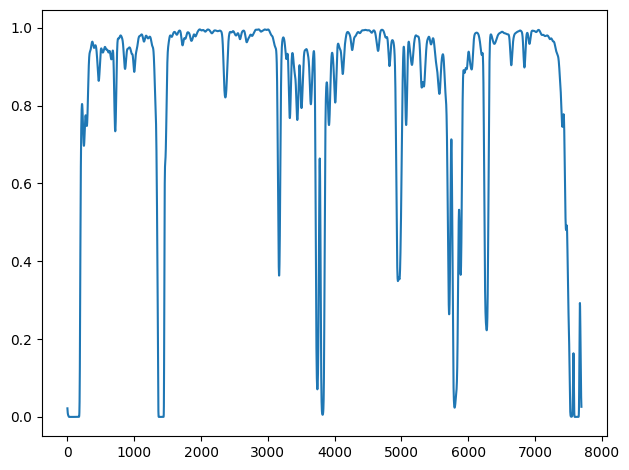

In [879]:
spec_num = 1

flux  = spectra_dict[spec_num]['Flux']
NHIs  = spectra_dict[spec_num]['NHI']
print(len(NHIs))

plt.plot(vel_grid, flux)

plt.tight_layout()
plt.show()

Started CDDF computation!


/tmp/ipykernel_1227729/924042844.py:38: RuntimeWarning: divide by zero encountered in log10
  plt.plot(np.log10(binc.to_value(1/u.cm**2)), np.log10(f.to_value(u.cm**2)))


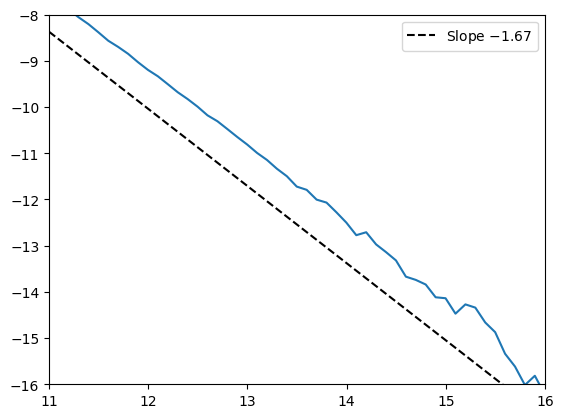

In [809]:
print("Started CDDF computation!")

NHIs = np.concatenate([
    spectra_dict[idx]['NHI']
    for idx in spectra_dict
])
    
NHIs = NHIs[NHIs > 0 * u.cm**-2]

#
nsight = num_spectra
box_pr = spectrum_setup.boxSizePr
H0     = spectrum_setup.cosmo_dict['Constants']['H0']
z      = spectrum_setup.z

# Logarithmic bins
bins = 10**np.arange(np.log10(np.min(NHIs.value)),
                     np.log10(np.max(NHIs.value)), 0.1)

binc = 0.5 * (bins[1:] + bins[:-1]) * NHIs.unit
widths = np.diff(bins) * NHIs.unit

# Bin counts
counts, _ = np.histogram(NHIs.value, bins=bins)

# dn/dN (linear CDDF before pathlength corrections)
dn_dNHI = counts / widths / nsight

# CDDF formula
f = ((dn_dNHI / box_pr) * (const.c / (H0 * (1+z)**3))).to(u.cm**2)

# Poisson errors (in log10 space)
# σ_log = 1 / (ln10 * sqrt(Nbin))
sigma_log = np.zeros_like(counts, dtype=float)
nonzero = counts > 0
sigma_log[nonzero] = (1 / np.log(10)) * (1 / np.sqrt(counts[nonzero]))

plt.plot(np.log10(binc.to_value(1/u.cm**2)), np.log10(f.to_value(u.cm**2)))
plt.xlim(11, 16)
plt.ylim(-16, -8)

# Reference power law with slope -1.67
x_ref = np.linspace(11, 16, 100)
y_ref = -1.67 * x_ref + 10  # Adjust intercept to position the line

plt.plot(x_ref, y_ref, 'k--', label=r'Slope $-1.67$')
plt.legend()

Started flux PDF computation!


<ErrorbarContainer object of 3 artists>

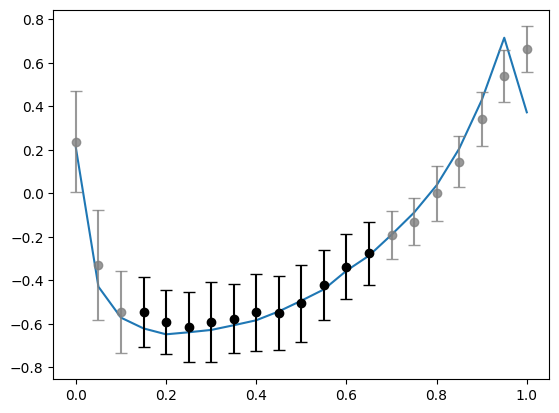

In [713]:
nsight = num_spectra

print("Started flux PDF computation!")

flux            = all_flux

#
bin_centres     = np.linspace(0, 1, 21)
dx              = bin_centres[1] - bin_centres[0]
bin_edges       = np.empty(len(bin_centres) + 1)
bin_edges[1:-1] = bin_centres[:-1] + dx/2
bin_edges[0]    = bin_centres[0] - dx/2
bin_edges[-1]   = bin_centres[-1] + dx/2

#
counts, _ = np.histogram(flux, bins = bin_edges, density = True)
pdf = counts
# mean_flux = np.mean(flux)

plt.plot(bin_centres, np.log10(pdf))

# Kim et al 2021 data
F = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 
     0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.00])
z299_raw = np.array([1.729, 0.471, 0.286, 0.285, 0.256, 0.243, 0.256, 0.266, 0.284, 0.281, 0.312,
        0.379, 0.459, 0.530, 0.644, 0.740, 0.999, 1.397, 2.188, 3.463, 4.601])
z299_err_raw = np.array([0.930, 0.274, 0.124, 0.107, 0.086, 0.091, 0.109, 0.098, 0.115, 0.110, 0.128,
            0.139, 0.158, 0.177, 0.166, 0.185, 0.291, 0.373, 0.623, 0.955, 1.099])

kim_valid_mask = (F > 0.1) & (F < 0.7)
kim_invalid_mask = ~kim_valid_mask

# Normalising Kim data
z299_pdf_norm = z299_raw 
z299_err_norm = z299_err_raw
eps = 1e-12
z299_pdf_safe = np.maximum(z299_pdf_norm, eps)

# Propagating errors into log10 space
log_pdf = np.log10(z299_pdf_safe)
log_pdf_err = z299_err_norm / (z299_pdf_safe * np.log(10))

plt.errorbar(F[kim_valid_mask], log_pdf[kim_valid_mask],
                   yerr=log_pdf_err[kim_valid_mask],
                   fmt='o', capsize=4, color='black',
                   label='Observations z̄ = 2.99')

plt.errorbar(F[kim_invalid_mask], log_pdf[kim_invalid_mask], yerr = log_pdf_err[kim_invalid_mask], fmt='o', capsize=4, color='gray', alpha = 0.8)


Started power spectrum computation!
Flux shape: (100, 7696)
Velocity grid length: 7696
Wavenumber shape: (3849,)
Mean power spectrum shape: (3849,)
ACF shape: (7696,)


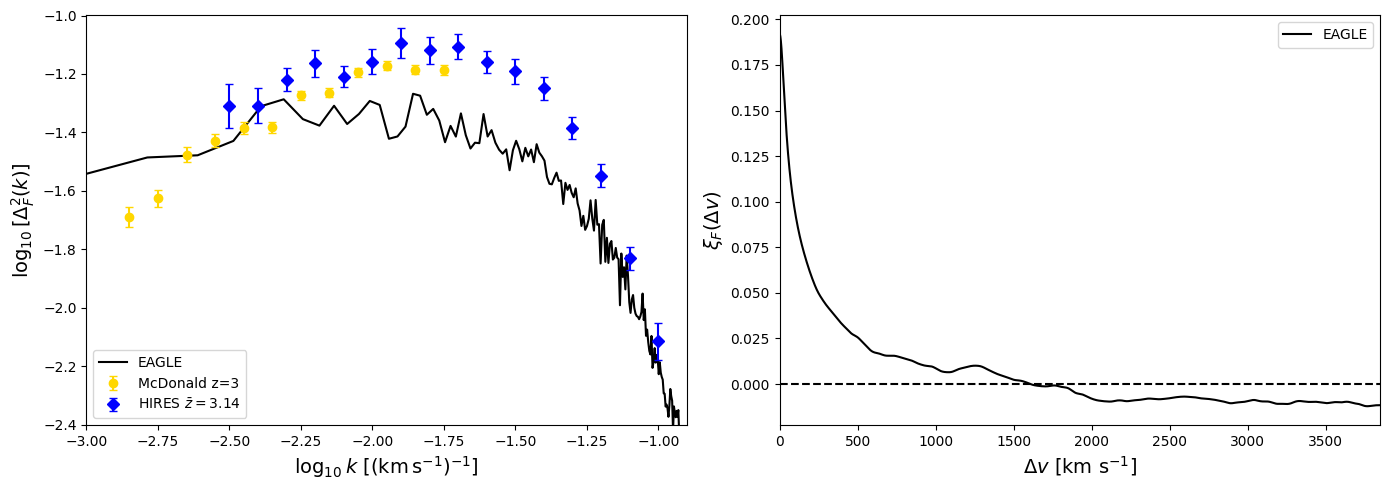

In [725]:

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import pandas as pd

print("Started power spectrum computation!")

# ============================================================
# 1. Extract flux spectra
# ============================================================

nsight = num_spectra
v_grid = vel_grid
npix = len(v_grid)
v_res = 1 * u.km / u.s

# Shape: (number of sightlines, number of velocity pixels)
flux = np.stack(
    [spectra_dict[i]['Flux'] for i in range(nsight)],
    axis=0
)

print("Flux shape:", flux.shape)
print("Velocity grid length:", npix)

assert flux.shape[1] == npix, (
    f"Flux has {flux.shape[1]} pixels per sightline, "
    f"but vel_grid has {npix} points."
)

# ============================================================
# 2. Fractional flux contrast
# ============================================================

mean_flux = np.mean(flux)

if mean_flux <= 0:
    raise ValueError("Mean flux must be positive.")

flux_contr = (flux / mean_flux) - 1

# ============================================================
# 3. Fourier transform and 1D flux power spectrum
# ============================================================

F = np.fft.rfft(flux_contr, axis=1)

L = npix * v_res

# Power spectrum for each sightline
P = L * np.abs(F)**2 / npix**2

# Mean power spectrum over sightlines
P_mean = np.mean(P, axis=0)

# Wavenumbers in (km/s)^-1
ks = (
    2 * np.pi
    * np.fft.rfftfreq(
        npix,
        d=v_res.to_value(u.km / u.s)
    )
    / (u.km / u.s)
)

# ============================================================
# 4. Autocorrelation function
# ============================================================

xi = npix * np.fft.irfft(P, n=npix, axis=1) / L
xi_mean = np.mean(xi, axis=0)

# Velocity-space lags
lags = np.arange(npix) * v_res

# ============================================================
# 5. Store results
# ============================================================

pa_dict = {
    'eagle': {
        'k': ks,
        'Pk': P_mean,
        'lags': lags,
        'Ac': xi_mean
    }
}

print("Wavenumber shape:", ks.shape)
print("Mean power spectrum shape:", P_mean.shape)
print("ACF shape:", xi_mean.shape)

# ============================================================
# 6. Create two horizontal panels
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# ------------------------------------------------------------
# LEFT PANEL: Dimensionless flux power spectrum
# ------------------------------------------------------------

k_values = ks.to_value((u.km / u.s)**-1)
Pk_values = P_mean.to_value(u.km / u.s)

dimless_Pk = k_values * Pk_values / np.pi

mask = (k_values > 0) & (Pk_values > 0)

ax1.plot(
    np.log10(k_values[mask]),
    np.log10(dimless_Pk[mask]),
    label='EAGLE',
    color = 'black'
)

# McDonald z=3 data
SDSS_k = np.array([
    0.00141, 0.00178, 0.00224, 0.00282,
    0.00355, 0.00447, 0.00562, 0.00708,
    0.00891, 0.01122, 0.01413, 0.01778
])

SDSS_P = np.array([
    45.64, 41.83, 46.88, 41.53,
    36.46, 29.12, 29.86, 24.19,
    22.52, 18.87, 14.52, 11.50
])

SDSS_sigma = np.array([
    3.67, 2.83, 2.64, 2.16,
    1.70, 1.19, 1.06, 0.80,
    0.75, 0.67, 0.53, 0.48
])

SDSS_sigma_log = SDSS_sigma / (SDSS_P * np.log(10))

ax1.errorbar(
    np.log10(SDSS_k),
    np.log10(SDSS_k * SDSS_P / np.pi),
    yerr=SDSS_sigma_log,
    color='gold',
    label='McDonald z=3',
    fmt='o',
    capsize=3
)

# HIRES data
df_pk = pd.read_csv(
    "../data/table_7_lyman_alpha_power.txt",
    sep=r'\s+'
)

df_z = df_pk[np.isclose(df_pk["z"], 3.14)]

log10k = df_z["logk"].values
k_day = 10**log10k
Pk_day = df_z["Power.1"].values

dimless_Pk_day = k_day * Pk_day / np.pi
errors_day = df_z["(raw).1"].values

yerr_day = (1 / np.log(10)) * (errors_day / Pk_day)

ax1.errorbar(
    np.log10(k_day),
    np.log10(dimless_Pk_day),
    yerr=yerr_day,
    fmt='D',
    color='blue',
    label=r'HIRES $\bar z = 3.14$',
    capsize=3
)

ax1.set_xlabel(
    r'$\log_{10} k\ [(\mathrm{km\,s^{-1}})^{-1}]$', fontsize = 14
)
ax1.set_ylabel(r'$\log_{10}[\Delta_F^2(k)]$', fontsize = 14)
ax1.set_xlim(-3, -0.9)
ax1.set_ylim(-2.4, -1)
ax1.legend()

# ------------------------------------------------------------
# RIGHT PANEL: Autocorrelation function
# ------------------------------------------------------------

lags_values = lags.to_value(u.km / u.s)
xi_values = np.asarray(xi_mean)

ax2.plot(
    lags_values,
    xi_values,
    label='EAGLE',
    color = 'black'
)

ax2.set_xlabel(r'$\Delta v$ [km s$^{-1}$]', fontsize = 14)
ax2.set_ylabel(r'$\xi_F(\Delta v)$', fontsize = 14)
ax2.set_xlim(0, lags_values.max() / 2)
ax2.hlines(0, 0, lags_values.max() / 2, color = 'black', linestyle = '--')
ax2.legend()

# ============================================================
# 7. Final layout
# ============================================================

plt.tight_layout()
plt.show()
